# Primer codigo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Entorno de análisis configurado correctamente")
print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)

Matplotlib is building the font cache; this may take a moment.


Entorno de análisis configurado correctamente
Versión de Pandas: 3.0.6
Versión de NumPy: 2.4.6


In [10]:
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd().resolve()

# Si ejecutamos desde notebooks/, subimos a la raíz
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Ruta del dataset
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "atm_transactions.csv"

# Verificar que existe
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el dataset en: {DATA_PATH}"
    )

# Cargar datos
df = pd.read_csv(DATA_PATH)

print("Dataset cargado correctamente")
print(f"Registros: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

Dataset cargado correctamente
Registros: 30,156
Columnas: 12


In [3]:
print("INFORMACIÓN GENERAL DEL DATASET")
print("-" * 50)

df.info()

print("\nNOMBRES DE LAS COLUMNAS")
print("-" * 50)

for columna in df.columns:
    print(columna)

INFORMACIÓN GENERAL DEL DATASET
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 30156 entries, 0 to 30155
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   atmId                     30156 non-null  str  
 1   atmName                   30156 non-null  str  
 2   atmCity                   30156 non-null  str  
 3   atmAddress                30156 non-null  str  
 4   totalBalance              30156 non-null  int64
 5   numberIncomeTransaction   30156 non-null  int64
 6   numberOutcomeTransaction  30156 non-null  int64
 7   totalIncome               30156 non-null  int64
 8   totalOutcome              30156 non-null  int64
 9   totalNumberTransaction    30156 non-null  int64
 10  day                       30156 non-null  str  
 11  transactionTime           30156 non-null  str  
dtypes: int64(6), str(6)
memory usage: 2.8 MB

NOMBRES DE LAS COLUMNAS
------

In [4]:
print("VALORES NULOS POR COLUMNA")
print("-" * 50)

print(df.isnull().sum())

print("\nREGISTROS DUPLICADOS")
print("-" * 50)

print(df.duplicated().sum())

print("\nESTADÍSTICAS DESCRIPTIVAS")
print("-" * 50)

display(df.describe(include="all").T)

VALORES NULOS POR COLUMNA
--------------------------------------------------
atmId                       0
atmName                     0
atmCity                     0
atmAddress                  0
totalBalance                0
numberIncomeTransaction     0
numberOutcomeTransaction    0
totalIncome                 0
totalOutcome                0
totalNumberTransaction      0
day                         0
transactionTime             0
dtype: int64

REGISTROS DUPLICADOS
--------------------------------------------------
0

ESTADÍSTICAS DESCRIPTIVAS
--------------------------------------------------


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
atmId,30156,359,atm350000,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
atmName,30156,359,ALİAĞA BAĞLI ŞB,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
atmCity,30156,1,Izmir,30156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
atmAddress,30156,717,Ord. Prof. Dr. Ekrem Akurgal Caddesi No: 18 / A,252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
totalBalance,30156.0,NaN,NaN,NaN,24903.350245,12140.702121,0.0,15050.0,25820.0,35335.0,57050.0
numberIncomeTransaction,30156.0,NaN,NaN,NaN,48.157348,31.311923,0.0,16.0,50.0,76.0,100.0
numberOutcomeTransaction,30156.0,NaN,NaN,NaN,55.087711,33.360273,0.0,16.0,64.0,84.0,100.0
totalIncome,30156.0,NaN,NaN,NaN,3089.089733,2063.646238,0.0,1015.0,3145.0,4835.0,8440.0
totalOutcome,30156.0,NaN,NaN,NaN,3533.655989,2200.795855,0.0,1015.0,4075.0,5310.0,9710.0
totalNumberTransaction,30156.0,NaN,NaN,NaN,103.245059,61.045114,0.0,27.0,125.0,153.0,200.0


In [5]:
resumen_columnas = pd.DataFrame({
    "columna": df.columns,
    "tipo_dato": df.dtypes.astype(str).values,
    "valores_nulos": df.isnull().sum().values,
    "valores_unicos": df.nunique(dropna=True).values
})

resumen_columnas["porcentaje_nulos"] = (
    resumen_columnas["valores_nulos"] / len(df) * 100
).round(2)

display(resumen_columnas)

,columna,tipo_dato,valores_nulos,valores_unicos,porcentaje_nulos
0,atmId,str,0,359,0.0
1,atmName,str,0,359,0.0
2,atmCity,str,0,1,0.0
3,atmAddress,str,0,717,0.0
4,totalBalance,int64,0,8796,0.0
5,numberIncomeTransaction,int64,0,92,0.0
6,numberOutcomeTransaction,int64,0,72,0.0
7,totalIncome,int64,0,1549,0.0
8,totalOutcome,int64,0,1536,0.0
9,totalNumberTransaction,int64,0,162,0.0


In [6]:
palabras_fecha = [
    "date",
    "time",
    "fecha",
    "hora",
    "timestamp"
]

columnas_temporales = [
    columna
    for columna in df.columns
    if any(
        palabra in columna.lower()
        for palabra in palabras_fecha
    )
]

print("Posibles columnas temporales:")

for columna in columnas_temporales:
    print(f"\nColumna: {columna}")
    print(df[columna].head(5))

Posibles columnas temporales:

Columna: transactionTime
0    2020-01-01 00:00:00
1    2020-01-01 00:00:00
2    2020-01-01 00:00:00
3    2020-01-01 00:00:00
4    2020-01-01 00:00:00
Name: transactionTime, dtype: str


In [7]:
columnas_numericas = df.select_dtypes(
    include=["number"]
).columns

print("Variables numéricas encontradas:")
print(columnas_numericas.tolist())

if len(columnas_numericas) > 0:
    display(df[columnas_numericas].describe().T)
else:
    print("No se encontraron variables numéricas.")

Variables numéricas encontradas:
['totalBalance', 'numberIncomeTransaction', 'numberOutcomeTransaction', 'totalIncome', 'totalOutcome', 'totalNumberTransaction']


,count,mean,std,min,25%,50%,75%,max
totalBalance,30156.0,24903.350245,12140.702121,0.0,15050.0,25820.0,35335.0,57050.0
numberIncomeTransaction,30156.0,48.157348,31.311923,0.0,16.0,50.0,76.0,100.0
numberOutcomeTransaction,30156.0,55.087711,33.360273,0.0,16.0,64.0,84.0,100.0
totalIncome,30156.0,3089.089733,2063.646238,0.0,1015.0,3145.0,4835.0,8440.0
totalOutcome,30156.0,3533.655989,2200.795855,0.0,1015.0,4075.0,5310.0,9710.0
totalNumberTransaction,30156.0,103.245059,61.045114,0.0,27.0,125.0,153.0,200.0


In [8]:
palabras_denominacion = [
    "denomination",
    "denom",
    "bill",
    "note",
    "cassette",
    "billete",
    "denominacion"
]

columnas_denominacion = [
    columna
    for columna in df.columns
    if any(
        palabra in columna.lower()
        for palabra in palabras_denominacion
    )
]

print("Columnas relacionadas con denominaciones:")
print(columnas_denominacion)

if not columnas_denominacion:
    print(
        "No se identificaron columnas de denominación "
        "por su nombre. Debemos revisar el significado "
        "de las demás variables."
    )

Columnas relacionadas con denominaciones:
[]
No se identificaron columnas de denominación por su nombre. Debemos revisar el significado de las demás variables.


In [11]:
# Verificar consistencia del número de transacciones

df["diferencia_transacciones"] = (
    df["totalNumberTransaction"]
    - (
        df["numberIncomeTransaction"]
        + df["numberOutcomeTransaction"]
    )
)

print("Distribución de diferencias:")
print(df["diferencia_transacciones"].value_counts())

print("\nRegistros inconsistentes:")
print((df["diferencia_transacciones"] != 0).sum())

Distribución de diferencias:
diferencia_transacciones
0    30156
Name: count, dtype: int64

Registros inconsistentes:
0


In [12]:
columnas_efectivo = [
    "totalBalance",
    "totalIncome",
    "totalOutcome"
]

display(df[columnas_efectivo].describe().T)

print("\nValores negativos:")

for columna in columnas_efectivo:
    negativos = (df[columna] < 0).sum()
    print(f"{columna}: {negativos}")

,count,mean,std,min,25%,50%,75%,max
totalBalance,30156.0,24903.350245,12140.702121,0.0,15050.0,25820.0,35335.0,57050.0
totalIncome,30156.0,3089.089733,2063.646238,0.0,1015.0,3145.0,4835.0,8440.0
totalOutcome,30156.0,3533.655989,2200.795855,0.0,1015.0,4075.0,5310.0,9710.0



Valores negativos:
totalBalance: 0
totalIncome: 0
totalOutcome: 0


In [13]:
print("Valores de la columna day:")
print(df["day"].unique())

print("\nPrimeros valores de transactionTime:")
print(df["transactionTime"].head(15).to_string(index=False))

print("\nÚltimos valores de transactionTime:")
print(df["transactionTime"].tail(15).to_string(index=False))

print("\nObservaciones por cajero:")
display(df.groupby("atmId").size().describe())

Valores de la columna day:
<StringArray>
['Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday', 'Monday', 'Tuesday']
Length: 7, dtype: str

Primeros valores de transactionTime:
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00
2020-01-01 00:00:00

Últimos valores de transactionTime:
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00
2020-01-07 23:00:00

Observaciones por cajero:


count    359.0
mean      84.0
std        0.0
min       84.0
25%       84.0
50%       84.0
75%       84.0
max       84.0
dtype: float64

In [14]:
# Crear una copia para no modificar los datos originales
df_analisis = df.copy()

# Convertir la columna temporal
df_analisis["transactionTime"] = pd.to_datetime(
    df_analisis["transactionTime"],
    errors="coerce"
)

# Ordenar por cajero y fecha
df_analisis = df_analisis.sort_values(
    by=["atmId", "transactionTime"]
).reset_index(drop=True)

print("Fecha mínima:")
print(df_analisis["transactionTime"].min())

print("\nFecha máxima:")
print(df_analisis["transactionTime"].max())

print("\nFechas inválidas:")
print(df_analisis["transactionTime"].isna().sum())

Fecha mínima:
2020-01-01 00:00:00

Fecha máxima:
2020-01-07 23:00:00

Fechas inválidas:
0


In [15]:
    # Diferencia temporal entre observaciones del mismo ATM
df_analisis["diferencia_horas"] = (
    df_analisis.groupby("atmId")["transactionTime"]
    .diff()
    .dt.total_seconds() / 3600
)

print("Distribución de intervalos entre registros:")

display(
    df_analisis["diferencia_horas"]
    .value_counts(dropna=True)
    .sort_index()
)

print("\nRegistros duplicados por cajero y fecha:")

duplicados = df_analisis.duplicated(
    subset=["atmId", "transactionTime"]
).sum()

print(duplicados)

Distribución de intervalos entre registros:


diferencia_horas
2.0    29797
Name: count, dtype: int64


Registros duplicados por cajero y fecha:
0


In [16]:
# Calcular variación del saldo por cajero
df_analisis["variacion_saldo"] = (
    df_analisis.groupby("atmId")["totalBalance"]
    .diff()
)

# Calcular flujo neto registrado
df_analisis["flujo_neto"] = (
    df_analisis["totalIncome"]
    - df_analisis["totalOutcome"]
)

# Comparar ambas cantidades
df_analisis["diferencia_contable"] = (
    df_analisis["variacion_saldo"]
    - df_analisis["flujo_neto"]
)

# Excluir primeras observaciones sin saldo anterior
comparacion = df_analisis.dropna(
    subset=["variacion_saldo"]
)

print("Registros comparados:", len(comparacion))

print("\nEstadísticas de diferencias contables:")

display(
    comparacion["diferencia_contable"].describe()
)

print("\nRegistros con diferencia distinta de cero:")

print(
    (comparacion["diferencia_contable"] != 0).sum()
)

Registros comparados: 29797

Estadísticas de diferencias contables:


count    29797.000000
mean       223.269624
std       5184.303273
min      -6890.000000
25%      -1275.000000
50%       -245.000000
75%        575.000000
max      44220.000000
Name: diferencia_contable, dtype: float64


Registros con diferencia distinta de cero:
29730


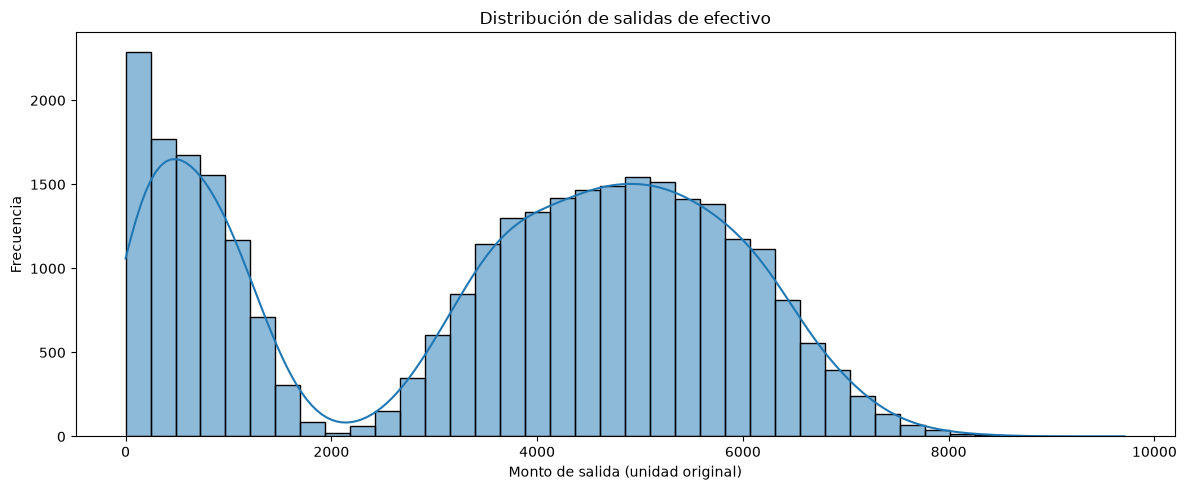

In [17]:
# Distribución de las salidas registradas
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_analisis,
    x="totalOutcome",
    bins=40,
    kde=True
)

plt.title("Distribución de salidas de efectivo")
plt.xlabel("Monto de salida (unidad original)")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()


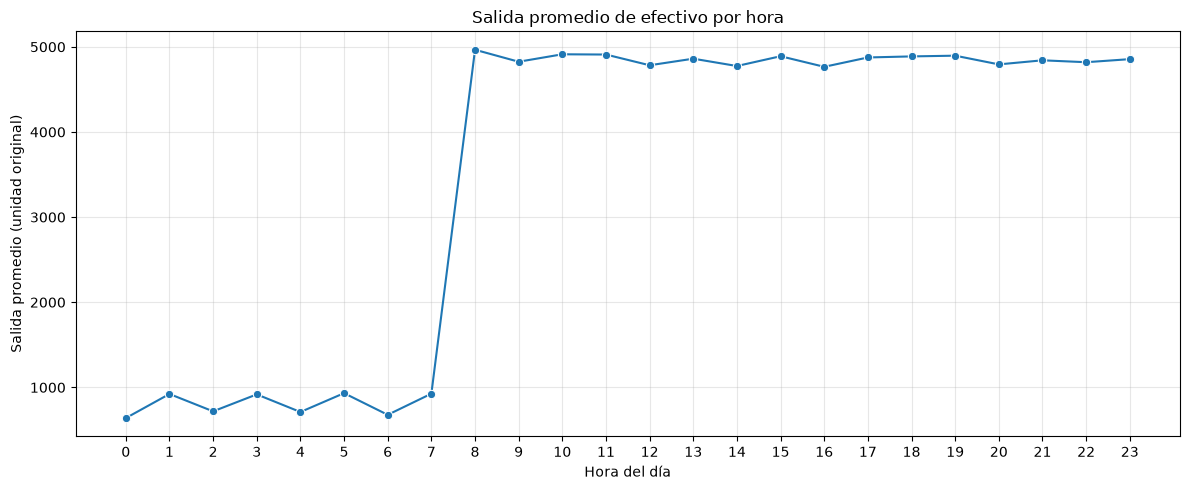

In [18]:
# Extraer hora del registro
df_analisis["hora"] = (
    df_analisis["transactionTime"].dt.hour
)

# Calcular salida promedio por hora
demanda_horaria = (
    df_analisis.groupby("hora")["totalOutcome"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=demanda_horaria,
    x="hora",
    y="totalOutcome",
    marker="o"
)

plt.title("Salida promedio de efectivo por hora")
plt.xlabel("Hora del día")
plt.ylabel("Salida promedio (unidad original)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

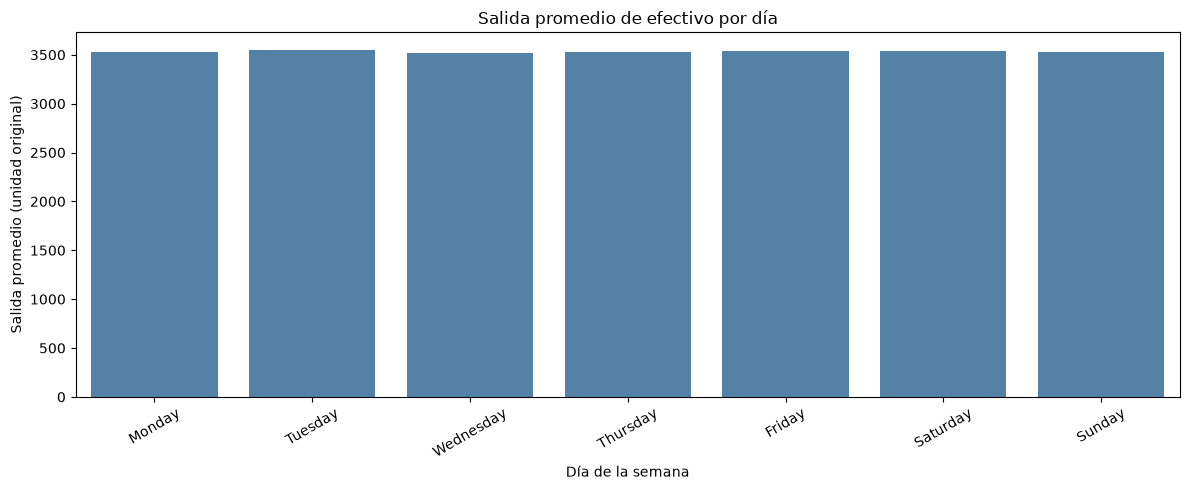

In [19]:
orden_dias = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

demanda_diaria = (
    df_analisis.groupby("day")["totalOutcome"]
    .mean()
    .reindex(orden_dias)
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=demanda_diaria,
    x="day",
    y="totalOutcome",
    color="steelblue"
)

plt.title("Salida promedio de efectivo por día")
plt.xlabel("Día de la semana")
plt.ylabel("Salida promedio (unidad original)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [20]:
demanda_atm = (
    df_analisis.groupby("atmId")
    .agg(
        salida_total=("totalOutcome", "sum"),
        salida_promedio=("totalOutcome", "mean"),
        registros=("totalOutcome", "size")
    )
    .sort_values(
        "salida_total",
        ascending=False
    )
)

display(demanda_atm.head(10))

,salida_total,salida_promedio,registros
atmId,,,
atm35000272,495465,5898.392857,84
atm35000314,494440,5886.190476,84
atm3500087,490110,5834.642857,84
atm35000167,489520,5827.619048,84
atm3500083,485110,5775.119048,84
atm3500056,483585,5756.964286,84
atm35000227,483235,5752.797619,84
atm35000124,483090,5751.071429,84
atm35000168,482405,5742.916667,84


In [21]:
# Día real calculado a partir de la fecha
df_analisis["dia_calculado"] = (
    df_analisis["transactionTime"].dt.day_name()
)

# Comparar contra la columna original
diferencias_dia = (
    df_analisis["day"]
    != df_analisis["dia_calculado"]
)

print("Registros con día inconsistente:")
print(diferencias_dia.sum())

print("\nEjemplos de diferencias:")

display(
    df_analisis.loc[
        diferencias_dia,
        ["transactionTime", "day", "dia_calculado"]
    ].head(10)
)

Registros con día inconsistente:
0

Ejemplos de diferencias:


,transactionTime,day,dia_calculado


In [22]:
# Estadísticas de salidas por hora
variabilidad_horaria = (
    df_analisis.groupby("hora")["totalOutcome"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

# Coeficiente de variación
variabilidad_horaria["cv"] = (
    variabilidad_horaria["std"]
    / variabilidad_horaria["mean"].replace(0, np.nan)
)

display(variabilidad_horaria)

,count,mean,std,min,max,cv
hora,,,,,,
0,518,639.60,734.99,0,6545,1.149140
1,1995,922.62,1288.41,0,8075,1.396469
2,518,718.75,762.83,0,7210,1.061329
3,1995,917.96,1253.79,0,7595,1.365844
4,518,710.97,743.93,0,7015,1.046359
5,1995,932.31,1293.90,0,8325,1.387843
6,518,677.92,728.81,0,6530,1.075068
7,1995,926.40,1255.10,0,7620,1.354814
8,518,4965.67,1136.90,2395,8370,0.228952


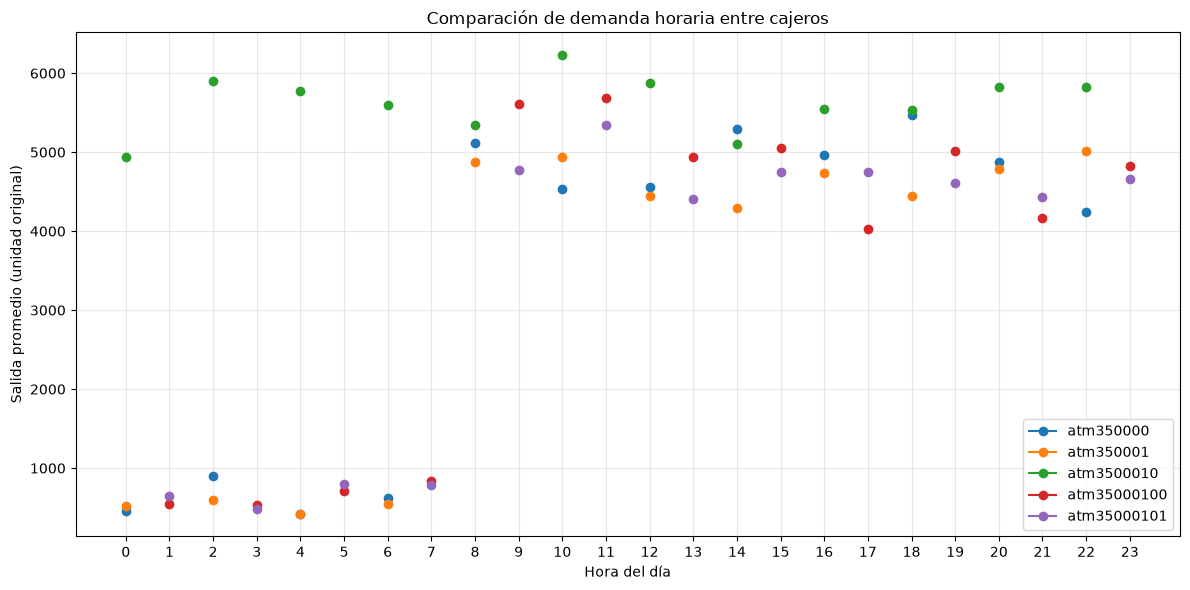

In [23]:
# Promedio horario para cada cajero
perfil_atm = (
    df_analisis.groupby(["atmId", "hora"])["totalOutcome"]
    .mean()
    .unstack()
)

# Seleccionar cinco cajeros de ejemplo
cajeros_ejemplo = perfil_atm.index[:5]

plt.figure(figsize=(12, 6))

for cajero in cajeros_ejemplo:
    plt.plot(
        perfil_atm.columns,
        perfil_atm.loc[cajero],
        marker="o",
        label=cajero
    )

plt.title("Comparación de demanda horaria entre cajeros")
plt.xlabel("Hora del día")
plt.ylabel("Salida promedio (unidad original)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# Crear una copia para el diagnóstico
df_temporal = df_analisis.copy()

# Identificar fecha y hora
df_temporal["fecha"] = (
    df_temporal["transactionTime"].dt.date
)

df_temporal["hora"] = (
    df_temporal["transactionTime"].dt.hour
)

# Resumen de cobertura por cajero
cobertura_atm = (
    df_temporal.groupby("atmId")
    .agg(
        registros=("transactionTime", "size"),
        fechas_unicas=("fecha", "nunique"),
        horas_unicas=("hora", "nunique"),
        fecha_inicio=("transactionTime", "min"),
        fecha_fin=("transactionTime", "max")
    )
)

print("Resumen de cobertura temporal:")
display(cobertura_atm.describe())

print("\nDistribución de horas únicas por cajero:")
print(cobertura_atm["horas_unicas"].value_counts())

print("\nPrimeros 10 cajeros:")
display(cobertura_atm.head(10))

print("\nDistribución de intervalos entre observaciones:")

display(
    df_temporal.groupby("atmId")["transactionTime"]
    .diff()
    .dt.total_seconds()
    .div(3600)
    .value_counts()
    .sort_index()
)


Resumen de cobertura temporal:


,registros,fechas_unicas,horas_unicas,fecha_inicio,fecha_fin
count,359.0,359.0,359.0,359,359
mean,84.0,7.0,12.0,2020-01-01 00:47:37.938718,2020-01-07 22:47:37.938718
min,84.0,7.0,12.0,2020-01-01 00:00:00,2020-01-07 22:00:00
25%,84.0,7.0,12.0,2020-01-01 01:00:00,2020-01-07 23:00:00
50%,84.0,7.0,12.0,2020-01-01 01:00:00,2020-01-07 23:00:00
75%,84.0,7.0,12.0,2020-01-01 01:00:00,2020-01-07 23:00:00
max,84.0,7.0,12.0,2020-01-01 01:00:00,2020-01-07 23:00:00
std,0.0,0.0,0.0,NaN,NaN



Distribución de horas únicas por cajero:
horas_unicas
12    359
Name: count, dtype: int64

Primeros 10 cajeros:


,registros,fechas_unicas,horas_unicas,fecha_inicio,fecha_fin
atmId,,,,,
atm350000,84,7,12,2020-01-01 00:00:00,2020-01-07 22:00:00
atm350001,84,7,12,2020-01-01 00:00:00,2020-01-07 22:00:00
atm3500010,84,7,12,2020-01-01 00:00:00,2020-01-07 22:00:00
atm35000100,84,7,12,2020-01-01 01:00:00,2020-01-07 23:00:00
atm35000101,84,7,12,2020-01-01 01:00:00,2020-01-07 23:00:00
atm35000102,84,7,12,2020-01-01 01:00:00,2020-01-07 23:00:00
atm35000103,84,7,12,2020-01-01 01:00:00,2020-01-07 23:00:00
atm35000104,84,7,12,2020-01-01 01:00:00,2020-01-07 23:00:00
atm35000105,84,7,12,2020-01-01 01:00:00,2020-01-07 23:00:00



Distribución de intervalos entre observaciones:


transactionTime
2.0    29797
Name: count, dtype: int64

In [25]:
# Comparar variaciones del saldo con movimientos registrados

df_contable = df_analisis.copy()

df_contable["saldo_anterior"] = (
    df_contable.groupby("atmId")["totalBalance"]
    .shift(1)
)

df_contable["variacion_saldo"] = (
    df_contable["totalBalance"]
    - df_contable["saldo_anterior"]
)

df_contable["flujo_neto"] = (
    df_contable["totalIncome"]
    - df_contable["totalOutcome"]
)

df_contable["diferencia_contable"] = (
    df_contable["variacion_saldo"]
    - df_contable["flujo_neto"]
)

# Excluir la primera observación de cada cajero
comparacion = df_contable.dropna(
    subset=["saldo_anterior"]
).copy()

print("Registros evaluados:", len(comparacion))

print("\nEstadísticas de diferencias contables:")
display(comparacion["diferencia_contable"].describe())

print("\nPorcentaje de registros con igualdad exacta:")

porcentaje_consistente = (
    comparacion["diferencia_contable"].eq(0).mean() * 100
)

print(f"{porcentaje_consistente:.2f}%")

print("\nEjemplos de registros:")
display(
    comparacion[
        [
            "atmId",
            "transactionTime",
            "saldo_anterior",
            "totalBalance",
            "totalIncome",
            "totalOutcome",
            "diferencia_contable"
        ]
    ].head(10)
)

Registros evaluados: 29797

Estadísticas de diferencias contables:


count    29797.000000
mean       223.269624
std       5184.303273
min      -6890.000000
25%      -1275.000000
50%       -245.000000
75%        575.000000
max      44220.000000
Name: diferencia_contable, dtype: float64


Porcentaje de registros con igualdad exacta:
0.22%

Ejemplos de registros:


,atmId,transactionTime,saldo_anterior,totalBalance,totalIncome,totalOutcome,diferencia_contable
1,atm350000,2020-01-01 02:00:00,40000.0,39850,485,1120,485.0
2,atm350000,2020-01-01 04:00:00,39850.0,39985,420,875,590.0
3,atm350000,2020-01-01 06:00:00,39985.0,38545,140,490,-1090.0
4,atm350000,2020-01-01 08:00:00,38545.0,39260,5220,4185,-320.0
5,atm350000,2020-01-01 10:00:00,39260.0,40475,6760,5335,-210.0
6,atm350000,2020-01-01 12:00:00,40475.0,40190,3555,4525,685.0
7,atm350000,2020-01-01 14:00:00,40190.0,39180,3205,4140,-75.0
8,atm350000,2020-01-01 16:00:00,39180.0,35715,3255,5750,-970.0
9,atm350000,2020-01-01 18:00:00,35715.0,34240,4950,4125,-2300.0
10,atm350000,2020-01-01 20:00:00,34240.0,30575,3305,5565,-1405.0


In [26]:
# Comparar diferentes hipótesis sobre el saldo

df_validacion = comparacion.copy()

# Hipótesis 1: saldo anterior + entradas - salidas
df_validacion["error_h1"] = (
    df_validacion["variacion_saldo"]
    - (
        df_validacion["totalIncome"]
        - df_validacion["totalOutcome"]
    )
)

# Hipótesis 2: saldo anterior - salidas
df_validacion["error_h2"] = (
    df_validacion["variacion_saldo"]
    + df_validacion["totalOutcome"]
)

# Hipótesis 3: saldo anterior + entradas
df_validacion["error_h3"] = (
    df_validacion["variacion_saldo"]
    - df_validacion["totalIncome"]
)

# Comparar resultados
resultados_hipotesis = pd.DataFrame({
    "hipotesis": [
        "Entradas - Salidas",
        "Solo salidas",
        "Solo entradas"
    ],
    "error_absoluto_medio": [
        df_validacion["error_h1"].abs().mean(),
        df_validacion["error_h2"].abs().mean(),
        df_validacion["error_h3"].abs().mean()
    ],
    "porcentaje_igualdad": [
        df_validacion["error_h1"].eq(0).mean() * 100,
        df_validacion["error_h2"].eq(0).mean() * 100,
        df_validacion["error_h3"].eq(0).mean() * 100
    ]
})

display(resultados_hipotesis)

,hipotesis,error_absoluto_medio,porcentaje_igualdad
0,Entradas - Salidas,1809.154445,0.224855
1,Solo salidas,3475.473705,0.083901
2,Solo entradas,4522.208108,0.057053


In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/atm_transactions.csv")

print("COLUMNAS:")
print(df.columns.tolist())

print("\nPRIMEROS 3 REGISTROS:")
print(df.head(3).to_string())

print("\nTIPOS DE DATOS:")
print(df.dtypes)

print("\nDIMENSIONES:")
print(df.shape)

COLUMNAS:
['atmId', 'atmName', 'atmCity', 'atmAddress', 'totalBalance', 'numberIncomeTransaction', 'numberOutcomeTransaction', 'totalIncome', 'totalOutcome', 'totalNumberTransaction', 'day', 'transactionTime']

PRIMEROS 3 REGISTROS:
       atmId                  atmName atmCity                  atmAddress  totalBalance  numberIncomeTransaction  numberOutcomeTransaction  totalIncome  totalOutcome  totalNumberTransaction        day      transactionTime
0  atm350000          ALİAĞA BAĞLI ŞB   Izmir     Aliağa Petkim Tesisleri         40000                        0                         0            0             0                       0  Wednesday  2020-01-01 00:00:00
1  atm350001  ALİAĞA İSTİKLAL CADDESİ   Izmir  ATATÜRK İSTİKLAL CD. NO:97         40000                        0                         0            0             0                       0  Wednesday  2020-01-01 00:00:00
2  atm350002         ALİAĞA PAZARYERİ   Izmir  ALİAĞA KAPALI PAZAR GİRİŞİ         40000              